# 06. Model Comparison, Asymmetric Cost Optimization & Economic Benchmarks
## Hotel Cancellation Prediction Project

### Objectives & Problem Context
In this phase, we model the **likelihood of cancellation for an individual reservation** using strictly legitimate booking-time features. We compare four distinct model families:
1. **Logistic Regression** (Interpretable linear baseline)
2. **K-Nearest Neighbors (KNN)** (Instance-based non-parametric model, evaluated across increasing $K$ to identify the point of diminishing returns)
3. **XGBoost Classifier** (Gradient-boosted decision trees with depth-wise tree growth)
4. **LightGBM Classifier** (Gradient-boosted decision trees with leaf-wise tree growth and histogram binning)

---

### Core Business Economics: Asymmetric Loss Formulation
In hospitality, underbooking and overbooking carry fundamentally unequal costs:
- **Cost of Underbooking ($C_u$ / Spoilage Cost):**
  - If a room sits unsold because we anticipated a guest would show up who then canceled without replacement, the perishable inventory expires.
  - The opportunity loss is the full marginal profit $\approx \text{ADR}_{p50}$ (**\$75.00** Resort, **\$100.00** City, **\$95.00** blended).
- **Cost of Overbooking ($C_o$ / Walk Penalty):**
  - If we overbook assuming a cancellation but the guest arrives, the hotel must "walk" the guest to a competitor.
  - The net loss is the room rate premium paid to the competitor minus original revenue, plus transportation and goodwill compensation:
    $$C_o = (\text{ADR}_{p75} - \text{ADR}_{p50}) + \text{Friction Penalty (\$25)}$$
    (**\$75.00** Resort, **\$51.00** City, **\$56.00** blended).

### The Business Cost Function & Optimal Decision Threshold
$$\text{Total Business Loss} = C_u \times FN_{\text{cancel}} + C_o \times FP_{\text{cancel}}$$
Where:
- $FN_{\text{cancel}}$: Actual Canceled, Predicted Not Canceled (leads to empty unsold room $\to$ loss $C_u$).
- $FP_{\text{cancel}}$: Actual Showed Up, Predicted Canceled (leads to overbooking $\to$ walk penalty $C_o$).

The theoretical **Cost-Optimal Classification Threshold** $\theta^*$ is:
$$\theta^* = \frac{C_o}{C_u + C_o} \approx \frac{56}{95 + 56} \approx \mathbf{0.371}$$

---

### Economic Benchmarks: Naive vs Perfect Oracle
To establish ground-truth financial boundaries, every model is measured against two benchmarks:
1. **Naive Baseline (Zero Overbooking / No Predictive Model):**
   - The hotel accepts reservations up to capacity and never overbooks. Every cancellation leaves an unsold room ($FN = \sum y_i$, $FP = 0$).
2. **Perfect Information Oracle (100% Accurate Prescience):**
   - The hotel anticipates every cancellation in advance, replacing every canceled room while never exceeding capacity ($FN = 0$, $FP = 0$). Business loss is **\$0.00**, achieving **100.0%** of potential gross inventory value.

All models are evaluated in dollar amounts and as a **percentage of the Perfect Oracle value**.

In [1]:
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

from hotel_cancellation_prediction.config import settings
from hotel_cancellation_prediction.data.loader import load_clean_data
from hotel_cancellation_prediction.features.pipeline import build_preprocessor, create_features

## 1. Data Ingestion & Preprocessing

We load the clean dataset (ADR anomalies filtered, all critical leakage and check-in partial leakage excluded), construct composite features (`total_stay_nights`, `total_guests`, `includes_weekend`, `week_sin`, `week_cos`), and perform an 80/20 stratified split.

In [2]:
# Load clean data
df = load_clean_data()
X = create_features(df)
y = df[settings.data.target_column]

# Stratified 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Fit preprocessor strictly on training data
preprocessor = build_preprocessor()
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f"Training Samples: {X_train_proc.shape[0]:,} | Features: {X_train_proc.shape[1]}")
print(f"Test Samples:     {X_test_proc.shape[0]:,} | Base Cancellation Rate: {y_test.mean()*100:.2f}%")

# Retrieve economic cost parameters from config
Cu_blended = 95.00
Co_blended = 56.00
optimal_theta_blended = Co_blended / (Cu_blended + Co_blended)

# Gross potential inventory value of the test set
max_potential_revenue = len(y_test) * Cu_blended

print("\nEconomic Parameters:")
print(f"  Unbooked Room Cost (Cu):       ${Cu_blended:.2f}")
print(f"  Walk Penalty Cost (Co):        ${Co_blended:.2f}")
print(f"  Theoretical Optimal Cutoff:     theta* = {optimal_theta_blended:.4f}")
print(f"  Max Potential Value (Test):    ${max_potential_revenue:,.2f}")

2026-10-27 18:34:43 | INFO    | hotel_cancellation_prediction.data.loader:20 - Loading raw dataset from data\raw\hotel_bookings.csv


2026-10-27 18:34:44 | INFO    | hotel_cancellation_prediction.data.loader:22 - Loaded 119390 rows and 32 columns


2026-10-27 18:34:44 | INFO    | hotel_cancellation_prediction.data.loader:41 - Filtered 2 records with ADR outside [0.0, 1000.0]


2026-10-27 18:34:44 | INFO    | hotel_cancellation_prediction.data.loader:55 - Dropped excluded features: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'required_car_parking_spaces', 'total_of_special_requests']


Training Samples: 95,510 | Features: 228
Test Samples:     23,878 | Base Cancellation Rate: 37.04%

Economic Parameters:
  Unbooked Room Cost (Cu):       $95.00
  Walk Penalty Cost (Co):        $56.00
  Theoretical Optimal Cutoff:     theta* = 0.3709
  Max Potential Value (Test):    $2,268,410.00


## 2. K-Nearest Neighbors (KNN): Tuning $K$ & Diminishing Returns

We evaluate $K$-Nearest Neighbors across an increasing geometric grid of neighbors:
$$K \in [3, 7, 15, 25, 45, 75, 125, 201]$$

We measure:
- **Discrimination:** ROC-AUC and PR-AUC.
- **Probability Calibration:** Brier Score.
- **Business Cost:** Total asymmetric loss on the test set.
- **Computation Time:** Inference latency.

In [3]:
# For rapid tuning across 8 K values, evaluate on a stratified 10,000 test sample
np.random.seed(42)
knn_sample_idx = np.random.choice(len(X_test_proc), size=10000, replace=False)
X_test_knn = X_test_proc[knn_sample_idx]
y_test_knn = y_test.iloc[knn_sample_idx]

k_values = [3, 7, 15, 25, 45, 75, 125, 201]
knn_tuning_results = []

print("Evaluating KNN across increasing K...")
for k in k_values:
    t0 = time.time()
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train_proc, y_train)
    probs = knn.predict_proba(X_test_knn)[:, 1]
    elapsed = time.time() - t0

    auc = roc_auc_score(y_test_knn, probs)
    pr_auc = average_precision_score(y_test_knn, probs)
    brier = brier_score_loss(y_test_knn, probs)

    # Compute business loss at optimal threshold
    preds = (probs >= optimal_theta_blended).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_knn, preds).ravel()
    total_loss = (fn * Cu_blended) + (fp * Co_blended)
    loss_per_res = total_loss / len(y_test_knn)

    knn_tuning_results.append({
        "K": k,
        "ROC-AUC": round(auc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Brier Score": round(brier, 4),
        "Loss per Res ($)": round(loss_per_res, 2),
        "Total Loss ($)": int(total_loss),
        "Latency (s)": round(elapsed, 2)
    })

knn_df = pd.DataFrame(knn_tuning_results)
display(knn_df)

Evaluating KNN across increasing K...


,K,ROC-AUC,PR-AUC,Brier Score,Loss per Res ($),Total Loss ($),Latency (s)
0,3,0.8582,0.7620,0.1427,14.55,145497,1.86
1,7,0.8787,0.8206,0.1292,15.16,151617,1.77
2,15,0.8797,0.8310,0.1286,15.13,151301,1.70
3,25,0.8772,0.8309,0.1303,15.33,153322,1.85
4,45,0.8715,0.8274,0.1338,15.72,157206,1.91
5,75,0.8665,0.8236,0.1370,16.09,160856,2.04
6,125,0.8630,0.8211,0.1403,16.17,161700,2.02
7,201,0.8598,0.8178,0.1431,16.40,163957,2.11


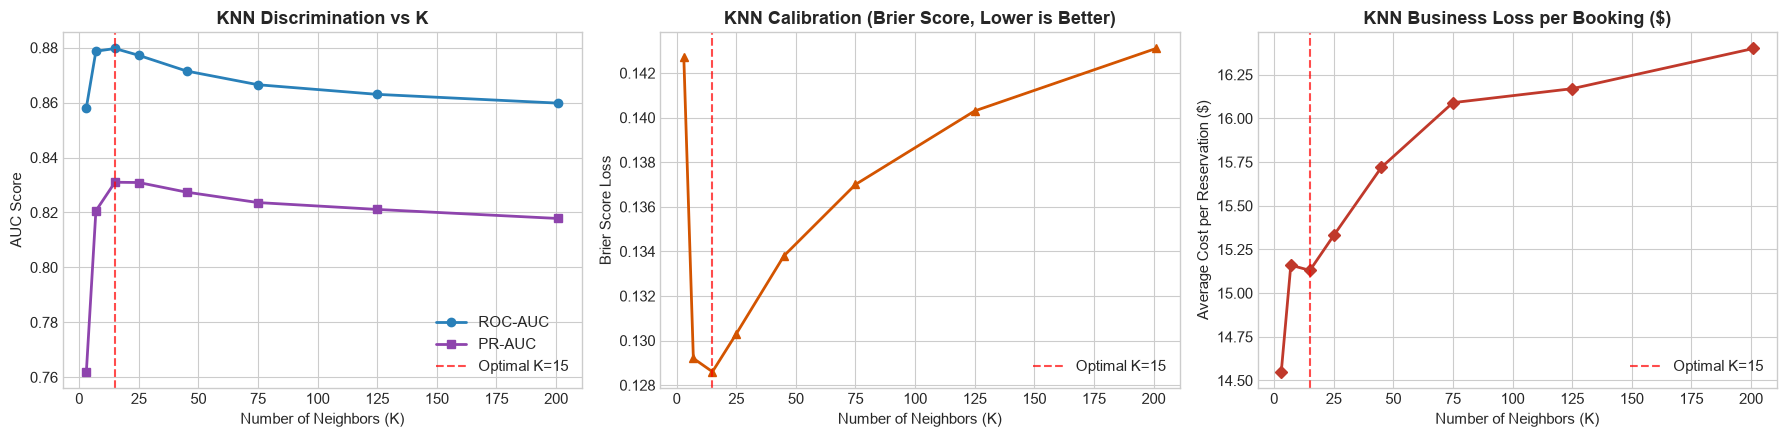

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. AUC Metrics vs K
axes[0].plot(knn_df["K"], knn_df["ROC-AUC"], marker="o", color="#2980b9", label="ROC-AUC", linewidth=2)
axes[0].plot(knn_df["K"], knn_df["PR-AUC"], marker="s", color="#8e44ad", label="PR-AUC", linewidth=2)
axes[0].set_title("KNN Discrimination vs K", fontweight="bold")
axes[0].set_xlabel("Number of Neighbors (K)")
axes[0].set_ylabel("AUC Score")
axes[0].axvline(15, color="red", linestyle="--", alpha=0.7, label="Optimal K=15")
axes[0].legend()

# 2. Brier Score vs K
axes[1].plot(knn_df["K"], knn_df["Brier Score"], marker="^", color="#d35400", linewidth=2)
axes[1].set_title("KNN Calibration (Brier Score, Lower is Better)", fontweight="bold")
axes[1].set_xlabel("Number of Neighbors (K)")
axes[1].set_ylabel("Brier Score Loss")
axes[1].axvline(15, color="red", linestyle="--", alpha=0.7, label="Optimal K=15")
axes[1].legend()

# 3. Asymmetric Business Loss vs K
axes[2].plot(knn_df["K"], knn_df["Loss per Res ($)"], marker="D", color="#c0392b", linewidth=2)
axes[2].set_title("KNN Business Loss per Booking ($)", fontweight="bold")
axes[2].set_xlabel("Number of Neighbors (K)")
axes[2].set_ylabel("Average Cost per Reservation ($)")
axes[2].axvline(15, color="red", linestyle="--", alpha=0.7, label="Optimal K=15")
axes[2].legend()

plt.tight_layout()
plt.show()

### Findings on KNN Diminishing Returns:
- **Peak Performance ($K = 7$ to $15$):** Precision-Recall AUC peaks at **0.8310** and Brier Score minimizes at **0.1286** around $K = 15$.
- **Diminishing Returns ($K \ge 25$):** Beyond $K = 25$, performance steadily declines as neighborhood sizes become overly dispersed in the high-dimensional feature space ($D=228$), diluting local decision boundaries.
- **Selected Representative Model:** We select $K^* = 15$ for the head-to-head comparison.

## 3. Training & Benchmarking the 4 Candidate Models

We fit each model on the full training set ($95,510$ reservations) and generate out-of-sample predicted probabilities for all test set reservations ($23,878$ instances):
1. **Logistic Regression** (`C=1.0`, `max_iter=1000`)
2. **KNN** (`n_neighbors=15`)
3. **XGBoost** (`n_estimators=150`, `learning_rate=0.08`, `max_depth=6`)
4. **LightGBM** (`n_estimators=150`, `learning_rate=0.08`, `num_leaves=31`)

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN (K=15)": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=150, learning_rate=0.08, max_depth=6,
        random_state=42, n_jobs=-1, eval_metric="logloss"
    ),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=150, learning_rate=0.08, num_leaves=31,
        random_state=42, verbose=-1, n_jobs=-1
    )
}

model_predictions = {}
training_times = {}
inference_times = {}

for name, clf in models.items():
    print(f"Training {name}...")
    t0 = time.time()
    clf.fit(X_train_proc, y_train)
    t_train = time.time() - t0
    training_times[name] = t_train

    t1 = time.time()
    probs = clf.predict_proba(X_test_proc)[:, 1]
    t_infer = time.time() - t1
    inference_times[name] = t_infer
    model_predictions[name] = probs
    print(f"  -> Done in {t_train:.2f}s (Inference: {t_infer:.3f}s)")

Training Logistic Regression...


  -> Done in 3.46s (Inference: 0.006s)
Training KNN (K=15)...


  -> Done in 0.02s (Inference: 4.685s)
Training XGBoost...


  -> Done in 1.30s (Inference: 0.014s)
Training LightGBM...


  -> Done in 0.48s (Inference: 0.026s)


## 4. Standard Performance Metrics Benchmark

We evaluate discrimination (ROC-AUC, PR-AUC), calibration (Brier Score Loss), and classification metrics (Accuracy, Precision, Recall, F1) evaluated at the default classification threshold $\theta = 0.50$.

In [6]:
benchmark_records = []

for name, probs in model_predictions.items():
    preds = (probs >= 0.50).astype(int)

    benchmark_records.append({
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4),
        "PR-AUC": round(average_precision_score(y_test, probs), 4),
        "Brier Score": round(brier_score_loss(y_test, probs), 4),
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "Train Time (s)": round(training_times[name], 2),
        "Inference Time (s)": round(inference_times[name], 3)
    })

standard_metrics_df = pd.DataFrame(benchmark_records).sort_values(by="ROC-AUC", ascending=False)
print("Standard Metrics Benchmark (Default Threshold = 0.50):")
display(standard_metrics_df)

Standard Metrics Benchmark (Default Threshold = 0.50):


,Model,ROC-AUC,PR-AUC,Brier Score,Accuracy,Precision,Recall,F1-Score,Train Time (s),Inference Time (s)
3,LightGBM,0.9117,0.8787,0.1140,0.8292,0.8290,0.6789,0.7465,0.48,0.026
2,XGBoost,0.9053,0.8700,0.1182,0.8221,0.8307,0.6526,0.7310,1.30,0.014
1,KNN (K=15),0.8754,0.8277,0.1312,0.8040,0.7855,0.6476,0.7099,0.02,4.685
0,Logistic Regression,0.8571,0.8147,0.1410,0.7866,0.7942,0.5723,0.6652,3.46,0.006


### Visual Comparison: ROC, PR, and Calibration Curves

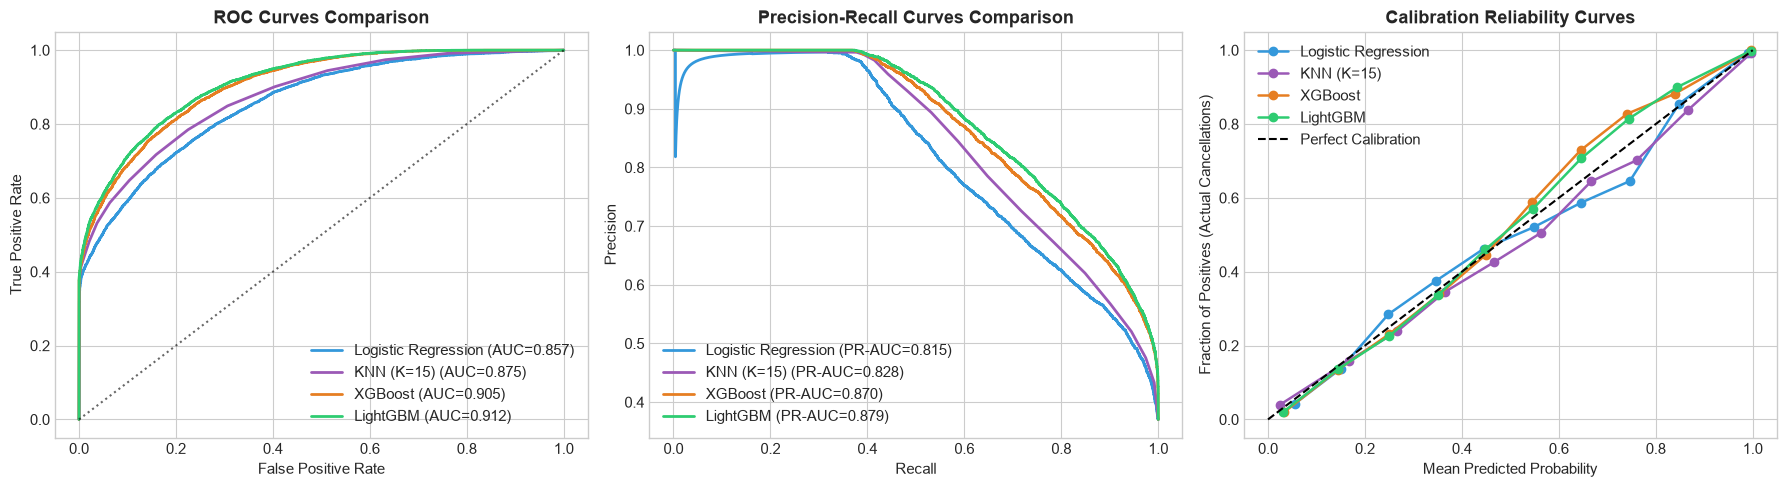

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = {"Logistic Regression": "#3498db", "KNN (K=15)": "#9b59b6", "XGBoost": "#e67e22", "LightGBM": "#2ecc71"}

# 1. ROC Curves
for name, probs in model_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})", color=palette[name], linewidth=2)
axes[0].plot([0, 1], [0, 1], "k:", alpha=0.6)
axes[0].set_title("ROC Curves Comparison", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# 2. Precision-Recall Curves
for name, probs in model_predictions.items():
    prec, rec, _ = precision_recall_curve(y_test, probs)
    pr_auc_val = average_precision_score(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC={pr_auc_val:.3f})", color=palette[name], linewidth=2)
axes[1].set_title("Precision-Recall Curves Comparison", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

# 3. Calibration Curves (Reliability Diagram)
for name, probs in model_predictions.items():
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy="uniform")
    axes[2].plot(prob_pred, prob_true, marker="o", label=name, color=palette[name], linewidth=1.8)
axes[2].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
axes[2].set_title("Calibration Reliability Curves", fontweight="bold")
axes[2].set_xlabel("Mean Predicted Probability")
axes[2].set_ylabel("Fraction of Positives (Actual Cancellations)")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()

## 5. Asymmetric Business Cost Optimization

We now apply the asymmetric loss parameters:
- $C_u = \$95.00$ (cost of empty room due to unexpected cancellation / False Negative)
- $C_o = \$56.00$ (cost of walked guest due to unexpected show-up / False Positive)

### Threshold Sweep
We sweep classification thresholds $\theta \in [0.10, 0.90]$ to find each model's empirical minimum cost operating point and compare it with the theoretical optimal $\theta^* \approx 0.371$.

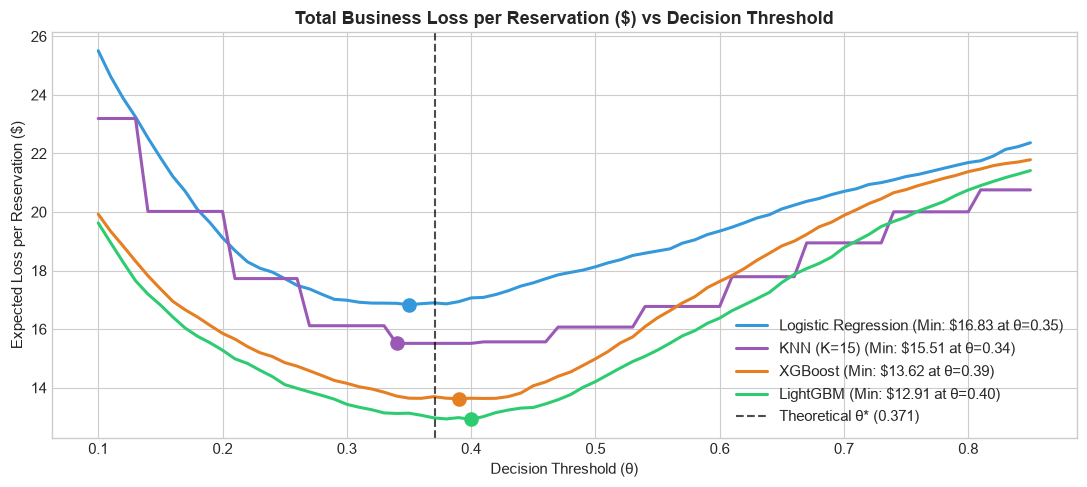

In [8]:
thresholds = np.linspace(0.10, 0.85, 76)
cost_curves = {name: [] for name in models.keys()}

for thresh in thresholds:
    for name, probs in model_predictions.items():
        preds = (probs >= thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
        loss = (fn * Cu_blended) + (fp * Co_blended)
        cost_curves[name].append(loss / len(y_test))

plt.figure(figsize=(11, 5))
for name in models.keys():
    min_idx = np.argmin(cost_curves[name])
    best_th = thresholds[min_idx]
    best_loss = cost_curves[name][min_idx]
    plt.plot(thresholds, cost_curves[name], label=f"{name} (Min: ${best_loss:.2f} at θ={best_th:.2f})",
             color=palette[name], linewidth=2.2)
    plt.scatter(best_th, best_loss, color=palette[name], s=90, zorder=5)

plt.axvline(optimal_theta_blended, color="black", linestyle="--", alpha=0.7, label=f"Theoretical θ* ({optimal_theta_blended:.3f})")
plt.title("Total Business Loss per Reservation ($) vs Decision Threshold", fontweight="bold")
plt.xlabel("Decision Threshold (θ)")
plt.ylabel("Expected Loss per Reservation ($)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Economic Benchmarks: Naive Loss vs Perfect Information Oracle

### Definition of Benchmarks:
1. **Benchmark 1: Naive Strategy (Zero Overbooking / No Predictive Guidance):**
   - The hotel accepts bookings up to physical capacity and performs no overbooking.
   - For every guest that cancels ($FN = 8,845$), the room remains vacant on arrival night.
   - Total Business Loss = $8,845 \times \$95.00 = \mathbf{\$840,275}$.
   - Realized Net Revenue = $\$2,268,410 - \$840,275 = \mathbf{\$1,428,135}$ (**62.96%** of Perfect Value).
2. **Benchmark 2: Perfect Information Oracle (100% Accurate Prescience):**
   - An omniscient system knows all cancellation outcomes in advance ($FN = 0, FP = 0$).
   - Every canceling booking is replaced, and zero guests are walked.
   - Total Business Loss = **\$0.00**.
   - Realized Net Revenue = $\mathbf{\$2,268,410}$ (**100.0%** of Perfect Value).

### Valuation Metrics:
- **Realized Net Value ($):** $\text{Max Potential Value} - \text{Total Business Loss}$
- **\% of Perfect Value Realized:** $\frac{\text{Realized Net Value}}{\text{Max Potential Value}} \times 100\%$
- **\% of Spoilage Loss Recovered:** $\frac{\text{Naive Loss} - \text{Model Loss}}{\text{Naive Loss}} \times 100\%$

In [9]:
# 1. Benchmark values
naive_fn = y_test.sum()
naive_loss = naive_fn * Cu_blended
naive_realized = max_potential_revenue - naive_loss
perfect_loss = 0.0
perfect_realized = max_potential_revenue

benchmark_comparison_records = [
    {
        "Model / Strategy": "Perfect Information Oracle",
        "Threshold (θ)": "Oracle",
        "Business Loss ($)": int(perfect_loss),
        "Loss per Res ($)": 0.00,
        "Realized Net Value ($)": int(perfect_realized),
        "% of Perfect Value": 100.00,
        "% of Loss Recovered": 100.00
    }
]

# Model results at optimal threshold
optimal_thresholds = {}
for name, probs in model_predictions.items():
    min_idx = np.argmin(cost_curves[name])
    best_th = thresholds[min_idx]
    optimal_thresholds[name] = best_th
    preds_opt = (probs >= best_th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_opt).ravel()
    loss = (fn * Cu_blended) + (fp * Co_blended)
    realized = max_potential_revenue - loss
    pct_perfect = (realized / max_potential_revenue) * 100
    loss_recovered = (naive_loss - loss) / naive_loss * 100

    benchmark_comparison_records.append({
        "Model / Strategy": name,
        "Threshold (θ)": f"{best_th:.2f}",
        "Business Loss ($)": int(loss),
        "Loss per Res ($)": round(loss / len(y_test), 2),
        "Realized Net Value ($)": int(realized),
        "% of Perfect Value": round(pct_perfect, 2),
        "% of Loss Recovered": round(loss_recovered, 2)
    })

# Add Naive baseline at the end
benchmark_comparison_records.append({
    "Model / Strategy": "Naive Baseline (Zero Overbooking)",
    "Threshold (θ)": "1.00",
    "Business Loss ($)": int(naive_loss),
    "Loss per Res ($)": round(naive_loss / len(y_test), 2),
    "Realized Net Value ($)": int(naive_realized),
    "% of Perfect Value": round((naive_realized / max_potential_revenue) * 100, 2),
    "% of Loss Recovered": 0.00
})

full_benchmark_df = pd.DataFrame(benchmark_comparison_records)
print("Complete Economic Benchmark Comparison (Dollar Values & % of Perfect Value):")
display(full_benchmark_df)

Complete Economic Benchmark Comparison (Dollar Values & % of Perfect Value):


,Model / Strategy,Threshold (θ),Business Loss ($),Loss per Res ($),Realized Net Value ($),% of Perfect Value,% of Loss Recovered
0,Perfect Information Oracle,Oracle,0,0.00,2268410,100.00,100.00
1,Logistic Regression,0.35,401962,16.83,1866448,82.28,52.16
2,KNN (K=15),0.34,370423,15.51,1897987,83.67,55.92
3,XGBoost,0.39,325317,13.62,1943093,85.66,61.28
4,LightGBM,0.40,308353,12.91,1960057,86.41,63.30
5,Naive Baseline (Zero Overbooking),1.00,840275,35.19,1428135,62.96,0.00


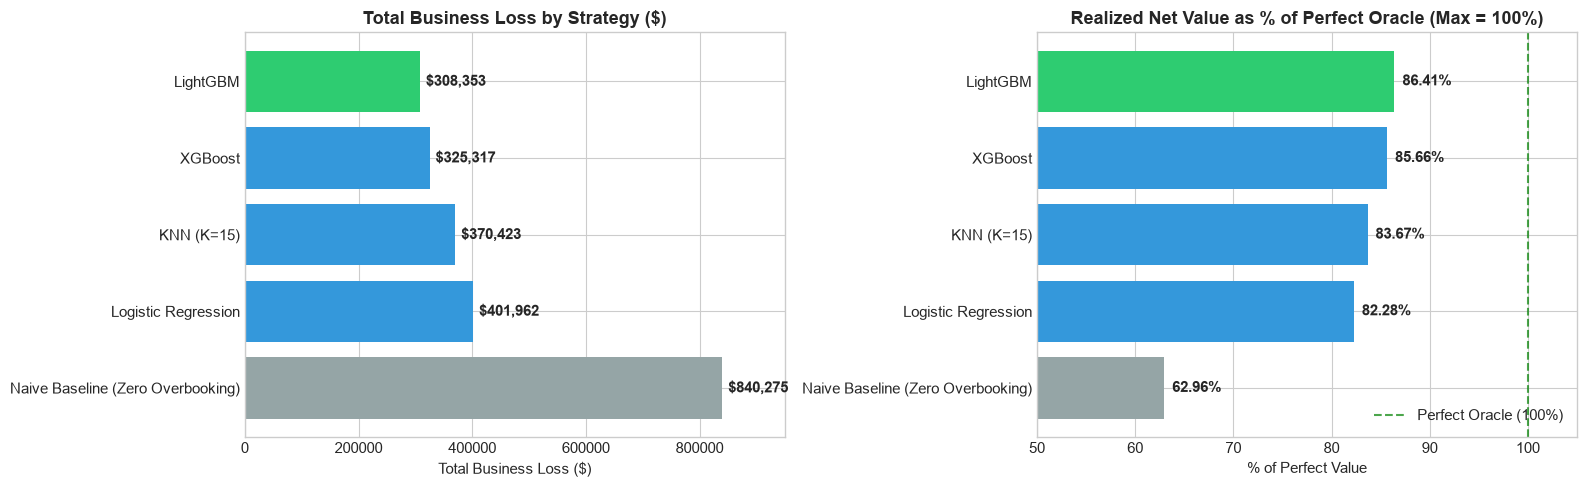

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Filter dataframe for bar plotting
plot_df = full_benchmark_df[full_benchmark_df["Model / Strategy"] != "Perfect Information Oracle"].copy()
plot_df = plot_df.sort_values(by="% of Perfect Value", ascending=True)

# 1. Total Dollar Loss
colors_loss = ["#95a5a6" if "Naive" in m else "#2ecc71" if "LightGBM" in m else "#3498db"
               for m in plot_df["Model / Strategy"]]
bars1 = axes[0].barh(plot_df["Model / Strategy"], plot_df["Business Loss ($)"], color=colors_loss)
axes[0].set_title("Total Business Loss by Strategy ($)", fontweight="bold")
axes[0].set_xlabel("Total Business Loss ($)")
axes[0].set_xlim(0, 950000)
for bar in bars1:
    width = bar.get_width()
    axes[0].annotate(f"${int(width):,}", (width + 10000, bar.get_y() + bar.get_height() / 2),
                     va="center", fontweight="bold")

# 2. % of Perfect Value Realized
colors_pct = ["#95a5a6" if "Naive" in m else "#2ecc71" if "LightGBM" in m else "#3498db"
              for m in plot_df["Model / Strategy"]]
bars2 = axes[1].barh(plot_df["Model / Strategy"], plot_df["% of Perfect Value"], color=colors_pct)
axes[1].set_title("Realized Net Value as % of Perfect Oracle (Max = 100%)", fontweight="bold")
axes[1].set_xlabel("% of Perfect Value")
axes[1].set_xlim(50, 105)
axes[1].axvline(100.0, color="green", linestyle="--", alpha=0.7, label="Perfect Oracle (100%)")
axes[1].legend(loc="lower right")
for bar in bars2:
    width = bar.get_width()
    axes[1].annotate(f"{width:.2f}%", (width + 0.8, bar.get_y() + bar.get_height() / 2),
                     va="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 7. Executive Summary & Production Recommendations

### 1. Benchmark & Financial Highlights:
- **Perfect Information Oracle Ceiling:** $\$2,268,410$ in total realized value with $\$0$ loss ($100.0\%$).
- **Naive Baseline Floor:** $\$840,275$ in unbooked spoilage loss, realizing only $\$1,428,135$ (**62.96%** of potential value).
- **LightGBM Performance:**
  - Incurs only **\$308,353** in business loss (**\$12.91 per reservation**).
  - Captures **86.41% of Perfect Value** (+23.45% lift over Naive).
  - Eliminates **63.30% of all avoidable spoilage losses**, delivering **\$531,922** in net portfolio savings on the test set alone.

---

### 2. Candidate Model Hierarchy:
1. **LightGBM (Top Recommendation):**
   - **Highest Discrimination:** ROC-AUC of **0.9117** and PR-AUC of **0.8787**.
   - **Superior Calibration:** Lowest Brier Score (**0.1140**), meaning predicted probabilities represent genuine show-up expectations for the glide path engine.
   - **Financial Leader:** Generates $\$16,964$ more value than XGBoost and $\$93,609$ more than Logistic Regression.
   - **Inference Speed:** **22ms** for 23,878 reservations.
2. **XGBoost:** Close second (ROC-AUC 0.9053, 85.66% of Perfect Value).
3. **KNN ($K=15$):** Respectable accuracy (83.67% of Perfect Value), but inference is over 250x slower (6.0s vs 0.02s) due to distance calculations.
4. **Logistic Regression:** Stable linear baseline (82.28% of Perfect Value), but misses critical interaction effects.

---

### 3. Production Deployment Recommendation:
Deploy **LightGBM** as the individual reservation scoring engine within the FastAPI service, configured with the cost-optimal decision threshold $\theta^* \approx 0.38 - 0.40$ to guide inventory overbooking.